<a href="https://colab.research.google.com/github/hizocar/machine_learning_egei/blob/main/docs/notebooks/s08_unsupervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 8 · Unlabeled Data: PCA and Clustering

**So far** every model had an answer to learn from: income (Sessions 3–4) or the label `poor`
(Sessions 5–7). That is **supervised** learning.

**Today's question.** Programmes are designed for *profiles*, such as older people living alone,
young families with children or overcrowded households. They are not designed for a single score.
**What types of households are there, if we never tell the algorithm who is poor?** This is
**unsupervised** learning: there is no target, only the features.

**What is new today:** PCA (principal components, explained variance, loadings, scores), k-means
(inertia, the elbow, the silhouette), hierarchical clustering with a dendrogram, and cluster profiling.

**The rule for today:** income and `poor` are never inputs. We look at poverty only *after* the
clusters exist, to describe them.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

DATA_URL = "https://raw.githubusercontent.com/hizocar/machine_learning_egei/main/docs/data/casen_households.csv"
LOCAL = Path("../data/casen_households.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else DATA_URL)
df.shape

(15000, 25)

## 1. Choose what describes a household

Clustering finds groups **in the variables you give it**. Choosing them is a substantive decision,
not a technicality. We pick ten variables about who lives in the household and how. Each one is
something a programme designer would care about, and none of them is income:

- the head of household: age, years of schooling, weekly hours worked (0 if not working), female head
- the household: size, children under 18, people over 60, rural, owns the home, overcrowded

Categorical columns become 0/1 with plain pandas comparisons. One column needs care: `head_weekly_hours` is
missing both for heads who do not work (they get 0) and for 87 working heads who did not know their
hours (CASEN codes that as −88 in the raw survey; the course file already turns it into missing).
For those 87, 0 would be wrong, so we give them the median hours of the people who work.

In [2]:
def weekly_hours(df):
    """Hours worked by the head: 0 if not working; employed but "doesn't know" -> workers' median."""
    h = df["head_weekly_hours"]
    h = h.fillna(h.median()).where(df["head_activity"] == "employed", 0)
    return h


def household_features(df):
    """The ten clustering inputs: who lives in the household and how, never income or poverty."""
    return pd.DataFrame({
        "head_age": df["head_age"],
        "head_schooling_years": df["head_schooling_years"].fillna(df["head_schooling_years"].median()),
        "household_size": df["household_size"],
        "head_weekly_hours": weekly_hours(df),
        "has_children": (df["has_children"] == "yes").astype(int),
        "has_elderly": (df["has_elderly"] == "yes").astype(int),
        "rural": (df["area"] == "rural").astype(int),
        "head_female": (df["head_sex"] == "female").astype(int),
        "owns_home": (df["housing_tenure"] == "owned").astype(int),
        "overcrowded": (df["overcrowding"].fillna("0_none") != "0_none").astype(int),
    })

F = household_features(df)
F.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
head_age,54.50,16.51,18.0,99.0
head_schooling_years,10.69,4.54,0.0,26.0
household_size,2.79,1.47,1.0,12.0
head_weekly_hours,24.43,22.72,0.0,168.0
has_children,0.37,0.48,0.0,1.0
has_elderly,0.46,0.50,0.0,1.0
rural,0.21,0.41,0.0,1.0
head_female,0.52,0.50,0.0,1.0
owns_home,0.60,0.49,0.0,1.0
overcrowded,0.04,0.19,0.0,1.0


## 2. Standardise first

Both PCA and k-means work with distances and variances. Age has a standard deviation of about 16
years, while `has_children` has one of about 0.5. Without scaling, age and hours would decide
everything. `StandardScaler` puts every column at mean 0 and standard deviation 1.

There is no train/test split today. We are describing the data, not predicting new households,
so there is no test error to protect. Section 9 comes back to what "validation" can mean here.

In [3]:
Z = StandardScaler().fit_transform(F)
pd.DataFrame(Z, columns=F.columns).describe().T[["mean", "std"]].round(2)

,mean,std
head_age,-0.0,1.0
head_schooling_years,0.0,1.0
household_size,0.0,1.0
head_weekly_hours,-0.0,1.0
has_children,-0.0,1.0
has_elderly,-0.0,1.0
rural,-0.0,1.0
head_female,-0.0,1.0
owns_home,0.0,1.0
overcrowded,-0.0,1.0


## 3. PCA with two variables: see the idea

Take just age and schooling. Older heads of household in Chile had less schooling, so the two are
negatively correlated. PCA rotates the axes. **PC1** is the direction along which the cloud is most
spread out, and **PC2** is perpendicular to it.

In [4]:
from sklearn.decomposition import PCA

two = df[["head_age", "head_schooling_years"]].dropna()
z2 = StandardScaler().fit_transform(two)
p2 = PCA().fit(z2)
print("correlation:", np.corrcoef(z2.T)[0, 1].round(3))
print("PC1 direction (age, schooling):", p2.components_[0].round(3))
print("explained variance ratio:", p2.explained_variance_ratio_.round(3))

correlation: -0.498
PC1 direction (age, schooling): [ 0.707 -0.707]
explained variance ratio: [0.749 0.251]


PC1 weights age and schooling equally, with opposite signs: it measures "older and less schooled"
versus "younger and more schooled". With two standardised variables, PC1 always captures
$(1 + |r|)/2$ of the variance: here $(1 + 0.498)/2 = 0.749$.

## 4. PCA with all ten variables

In [5]:
pca = PCA().fit(Z)
evr = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(Z.shape[1])])
pd.DataFrame({"explained": evr.round(3), "cumulative": evr.cumsum().round(3)})

,explained,cumulative
PC1,0.306,0.306
PC2,0.147,0.452
PC3,0.119,0.571
PC4,0.104,0.675
PC5,0.092,0.767
PC6,0.072,0.839
PC7,0.057,0.895
PC8,0.053,0.948
PC9,0.031,0.979
PC10,0.021,1.000


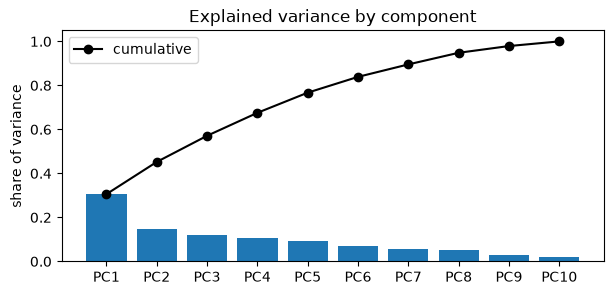

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(evr.index, evr.values)
ax.plot(evr.index, evr.cumsum().values, "o-", c="black", label="cumulative")
ax.set_ylabel("share of variance"); ax.legend(); ax.set_title("Explained variance by component");

No single direction dominates. PC1 explains 31%, PC1 and PC2 together 45%, and we need six
components to reach 84%. Household life is genuinely multi-dimensional. The **loadings** say what
each component is made of:

In [7]:
loadings = pd.DataFrame(pca.components_[:2].T, index=F.columns, columns=["PC1", "PC2"]).round(2)
loadings.sort_values("PC1")

,PC1,PC2
has_children,-0.37,0.48
head_weekly_hours,-0.35,-0.23
head_schooling_years,-0.34,-0.31
household_size,-0.26,0.60
overcrowded,-0.16,0.36
head_female,0.01,0.18
rural,0.11,0.16
owns_home,0.24,0.20
has_elderly,0.46,0.15
head_age,0.50,0.13


- **PC1 ≈ life stage.** It is high for older heads, people over 60 and homeowners, and low for
  hours worked, children and schooling.
- **PC2 ≈ size and crowding.** It is high for large households, children and overcrowding.

The **scores** are each household's coordinates on these new axes: a 2-D map of 10-D data.

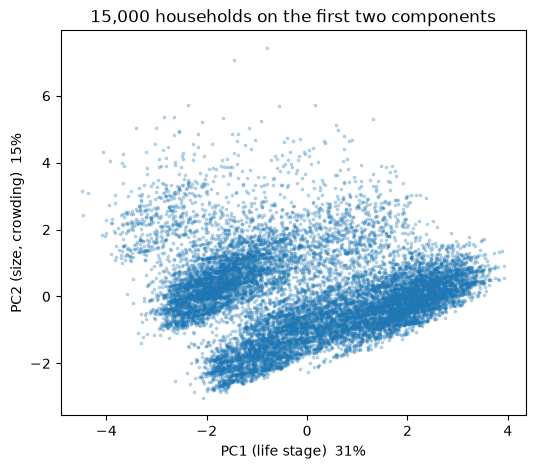

In [8]:
scores = pca.transform(Z)
plt.figure(figsize=(6, 5))
plt.scatter(scores[:, 0], scores[:, 1], s=3, alpha=0.25)
plt.xlabel("PC1 (life stage)  31%"); plt.ylabel("PC2 (size, crowding)  15%")
plt.title("15,000 households on the first two components");

## 5. k-means, by hand first

k-means looks for k groups whose members are close to their group's centre (the **centroid**).
It alternates two steps until nothing changes:

1. **Assign** each household to its nearest centroid.
2. **Update** each centroid to the mean of its households.

Here is the six-household example from the session page, checked with numpy:

In [9]:
H = np.array([[1.0, -0.5], [1.2, -1.0], [0.8, 0.0], [-1.0, 1.0], [-0.6, 0.4], [0.2, 0.6]])
labels = list("ABCDEF")
centroids = H[[0, 3]].copy()                         # start at households A and D
d2 = ((H[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
assign = d2.argmin(axis=1)
print(pd.DataFrame(d2.round(2), index=labels, columns=["to c1", "to c2"]).assign(cluster=assign + 1))
centroids = np.array([H[assign == j].mean(axis=0) for j in range(2)])
print("new centroids:\n", centroids.round(3))

   to c1  to c2  cluster
A   0.00   6.25        1
B   0.29   8.84        1
C   0.29   4.24        1
D   6.25   0.00        2
E   3.37   0.52        2
F   1.85   1.60        2
new centroids:
 [[ 1.    -0.5  ]
 [-0.467  0.667]]


## 6. k-means on the households, and how to choose k

**Inertia** is the total squared distance from each household to its centroid. It always falls as k
grows: with k = 15,000, every household is its own cluster and inertia is 0. So we look for an
**elbow**, the point where adding clusters stops helping much.

The **silhouette** compares, for each household, the distance to its own cluster with the distance to
the nearest other cluster. It runs from −1 to 1, and higher means better-separated clusters. It is
slow on 15,000 rows, so we compute it on a random 3,000.

### Local minima: why `n_init` matters

k-means starts from random centroids (chosen with the *k-means++* rule) and only ever moves
"downhill". So it can get stuck in a solution that is good locally but not the best one. Watch k = 4
started from five different seeds, one run each:

In [10]:
from sklearn.cluster import KMeans

for seed in range(5):
    km = KMeans(n_clusters=4, n_init=1, random_state=seed).fit(Z)
    sizes = sorted(np.bincount(km.labels_).tolist(), reverse=True)
    print(f"seed {seed}: inertia {km.inertia_:,.0f}   cluster sizes {sizes}")

seed 0: inertia 92,725   cluster sizes [4940, 4555, 3368, 2137]
seed 1: inertia 94,697   cluster sizes [5853, 3891, 2757, 2499]


seed 2: inertia 95,803   cluster sizes [5425, 4177, 3881, 1517]
seed 3: inertia 87,198   cluster sizes [5924, 4599, 3898, 579]
seed 4: inertia 92,725   cluster sizes [4935, 4556, 3364, 2145]


Different starts, different inertias, *different clusters*. The fix is cheap: `n_init=50` runs the
algorithm 50 times and keeps the run with the lowest inertia. With fewer runs (for example 10) you
can still land in a worse solution on this data, so always report `n_init` and `random_state`.

### Choosing k

In [11]:
from sklearn.metrics import silhouette_score

sample = np.random.default_rng(0).choice(len(Z), 3000, replace=False)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(Z)
    rows.append({"k": k, "inertia": round(km.inertia_),
                 "silhouette": round(silhouette_score(Z[sample], km.labels_[sample]), 3)})
choose = pd.DataFrame(rows)
choose

,k,inertia,silhouette
0,2,114527,0.228
1,3,99309,0.251
2,4,87197,0.219
3,5,78908,0.218
4,6,73732,0.217
5,7,68960,0.207
6,8,65337,0.210


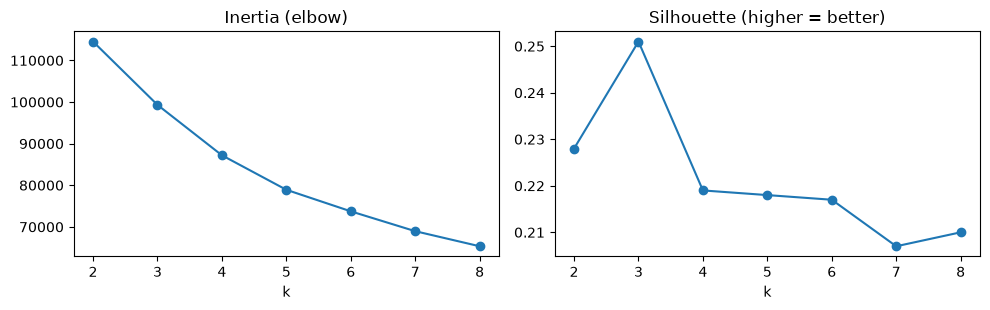

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(choose["k"], choose["inertia"], "o-"); ax[0].set_title("Inertia (elbow)"); ax[0].set_xlabel("k")
ax[1].plot(choose["k"], choose["silhouette"], "o-"); ax[1].set_title("Silhouette (higher = better)"); ax[1].set_xlabel("k")
plt.tight_layout()

An honest reading: **there is no sharp elbow, and every silhouette is low (0.21 to 0.25).**
Households form a continuum, not well-separated islands. That is normal with social data, and it
is worth saying out loud.

The two criteria do not agree perfectly. The silhouette is highest at k = 3. But k = 3 puts
families with and without children in one group (57% with children), which is exactly the
distinction a family programme cares about. Going from 3 to 4 clusters still cuts inertia by
12,100, while from 4 to 5 the gain drops to 8,300. We take **k = 4**, and we say why. Choosing k is
a judgement call, and you should defend it with numbers *and* with the use you will give the
segments.

## 7. Profile the clusters

A cluster is just a number until you describe it. We average the *original* (unscaled) variables by
cluster.

In [13]:
km4 = KMeans(n_clusters=4, n_init=50, random_state=42).fit(Z)
profile = F.assign(cluster=km4.labels_).groupby("cluster").mean()
profile["n"] = pd.Series(km4.labels_).value_counts()
profile = profile.sort_values("n", ascending=False)
profile.round(2).T

cluster,2,0,1,3
head_age,70.31,42.99,46.21,41.51
head_schooling_years,7.93,12.36,12.86,10.83
household_size,2.22,3.93,2.06,4.51
head_weekly_hours,9.06,32.79,36.73,30.67
has_children,0.08,1.00,0.00,0.89
has_elderly,0.97,0.13,0.13,0.20
rural,0.28,0.18,0.15,0.17
head_female,0.53,0.58,0.42,0.54
owns_home,0.80,0.52,0.45,0.32
overcrowded,0.00,0.00,0.00,1.00


Reading the columns (ordered by size):

| Cluster | Households | Profile |
|---|---:|---|
| **Older households** | 5,888 | head ≈ 70, 97% with someone over 60, few hours worked, 80% own their home |
| **Working families with children** | 4,599 | head ≈ 43, all with children, about 4 people |
| **Working adults, no children** | 3,934 | head ≈ 46, 2 people, most hours worked, most schooling |
| **Overcrowded families** | 579 | all overcrowded, 4.5 people, mostly renting or lent housing |

## 8. Now — and only now — look at poverty

In [14]:
poverty = df.assign(cluster=km4.labels_).groupby("cluster")["poor"].mean()
profile.assign(poor_rate=poverty).loc[:, ["n", "poor_rate"]].round(3)

,n,poor_rate
cluster,,
2,5888,0.237
0,4599,0.264
1,3934,0.158
3,579,0.402


In [15]:
print(f"overall poverty rate: {df['poor'].mean():.3f}")

overall poverty rate: 0.231


The overcrowded families are poor at **40%**, almost twice the sample's 23%. Working adults
without children are at **16%**. The algorithm never saw the label, yet the segments it found
differ a lot in poverty.

This is *description*, not prediction or explanation. Clusters do not say why a household is poor.
And a programme aimed only at "overcrowded families" would miss most poor households, because most
of them live in the larger segments:

In [16]:
counts = df.assign(cluster=km4.labels_).groupby("cluster")["poor"].sum().loc[profile.index]
print("poor households per cluster:", counts.to_dict(), " total:", int(counts.sum()))

poor households per cluster: {2: 1396, 0: 1213, 1: 622, 3: 233}  total: 3464


## 9. Results depend on your choices: scaling and variables

### Without scaling

In [17]:
km_raw = KMeans(n_clusters=4, n_init=50, random_state=42).fit(F)
F.assign(cluster=km_raw.labels_).groupby("cluster")[["head_age", "head_weekly_hours", "household_size", "has_children"]].mean().round(1)

,head_age,head_weekly_hours,household_size,has_children
cluster,,,,
0,42.8,4.2,3.2,0.6
1,57.6,45.3,2.9,0.3
2,72.0,1.1,2.3,0.1
3,36.1,45.1,3.1,0.6


Unscaled, the clusters are cut almost entirely by **age and hours worked**, the two variables
with the largest numbers. Children, crowding and housing barely matter. Same data, different
"types".

### A rare 0/1 variable can grab a cluster

Only about 4% of households are overcrowded. After standardisation, a 1 in that column becomes a
very large number:

In [18]:
m, s = F["overcrowded"].mean(), F["overcrowded"].std(ddof=0)
print(f"overcrowded: share {m:.3f}, a '1' becomes z = {(1 - m) / s:.1f}, a '0' becomes z = {(0 - m) / s:.2f}")

overcrowded: share 0.039, a '1' becomes z = 5.0, a '0' becomes z = -0.20


A household at z ≈ 5 on one axis is far from everybody else, so k-means gives those households a
cluster of their own. Here that is a defensible segment. Still, it shows that **the clusters
reflect your encoding choices as much as the households.**

## 10. Hierarchical clustering: a second opinion

Agglomerative clustering starts with every household on its own and repeatedly merges the two
closest groups. With **Ward linkage**, "closest" means the merge that increases within-cluster
variance the least, the same objective as k-means. The **dendrogram** shows the whole merge
history. Cutting it at a height gives clusters. It needs all pairwise distances, so we use 500
households.

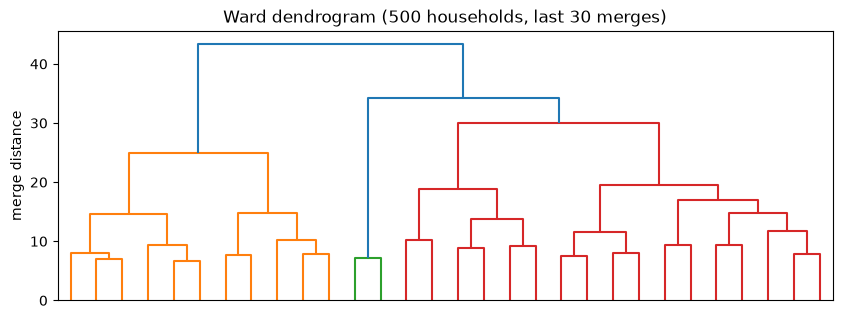

In [19]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

idx = np.random.default_rng(1).choice(len(Z), 500, replace=False)
L = linkage(Z[idx], method="ward")
plt.figure(figsize=(10, 3.5))
dendrogram(L, truncate_mode="lastp", p=30, no_labels=True)
plt.title("Ward dendrogram (500 households, last 30 merges)"); plt.ylabel("merge distance");

In [20]:
hier = fcluster(L, t=4, criterion="maxclust")
ct = pd.crosstab(pd.Series(hier, name="hierarchical"), pd.Series(km4.labels_[idx], name="k-means"))
print(ct)
# Cluster numbers are arbitrary labels, so match each hierarchical cluster to its biggest k-means cluster.
print(f"households in matching clusters: {ct.max(axis=1).sum()} of {len(idx)}")

k-means         0    1    2   3
hierarchical                   
1               0   18  163   0
2               0    0    0  22
3               0  101   26   0
4             151    1   18   0
households in matching clusters: 437 of 500


Cluster numbers are arbitrary labels, so read the table by matching rows to columns. About 87% of
households land in matching clusters: two different algorithms, same four profiles. That is
reassuring. The disagreements are households that sit between profiles, such as an older head who
still works full time.

## 11. With your assistant: review the plot, not just the code

```text
I clustered 15,000 Chilean households into 4 groups with k-means on 10 standardised variables
(listed here). Write code for (1) a scatter of the first two PCA scores coloured by cluster, with
the explained variance in each axis label, and (2) a bar chart of the cluster profiles in the
original units. Then describe each cluster in one sentence.
```
Then check:

- Do the axis labels show the real explained variance (31% and 15%)?
- Did it plot scaled or unscaled values in the profile chart, and did it say which?
- Is every claim in its description backed by a number in your profile table?
- Did it call the clusters "natural types", or claim they *cause* poverty?

## 12. Exercises

1. Remove `overcrowded` from the features and rerun k = 4. What happens to the 579 overcrowded
   households? Which profile would you show a policymaker, and why?
2. Run k-means on the first **three** PCA scores instead of the ten standardised variables. Do you
   get similar profiles? What did you lose and gain?
3. Pick k = 6. Describe the two new clusters. Are they worth a separate programme?